# 01 — The data: 118 elements (Labs 1–2)

**Project question:** if we cluster the chemical elements using *only* their physical
properties, does an unsupervised algorithm (K-Means, Session 11) rediscover the periodic
table's families?

**This notebook (Labs 1–2):** load the data, check what every column *is*, learn which cells
are missing *and why*, and lock in the leakage rule that keeps the experiment honest.

**Open in VS Code → kernel: `Python 3 (.venv)`. Runs offline: data snapshot is committed.**

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import load_elements

df = load_elements()
print(f"elements: {len(df)}  |  columns in snapshot: {df.shape[1]}")
df[["symbol", "atomic_weight", "density", "en_pauling"]].head(8)

elements: 118  |  columns in snapshot: 83


,symbol,atomic_weight,density,en_pauling
0,H,1.008000,0.000082,2.20
1,He,4.002602,0.000164,NaN
2,Li,6.940000,0.534000,0.98
3,Be,9.012183,1.850000,1.57
4,B,10.810000,2.340000,2.04
5,C,12.011000,2.200000,2.55
6,N,14.007000,0.001145,3.04
7,O,15.999000,0.001308,3.44


## 1. Feature coverage — what is measurable for every element?

Physical features we may use (and the *identity* columns that stay out of features later):

In [2]:
cands = ["atomic_weight", "density", "atomic_radius", "atomic_radius_rahm",
         "en_pauling", "electron_affinity", "group_id", "period", "block"]
cov = pd.DataFrame({"non_null": df[cands].notna().sum(),
                    "pct": (df[cands].notna().mean() * 100).round(1)})
cov.index.name = "column"
cov.to_csv(ROOT / "reports" / "tables" / "feature_coverage.csv")
cov

,non_null,pct
column,,
atomic_weight,118,100.0
density,118,100.0
atomic_radius,90,76.3
atomic_radius_rahm,96,81.4
en_pauling,85,72.0
electron_affinity,77,65.3
group_id,90,76.3
period,118,100.0
block,118,100.0


- **Complete for all 118:** atomic weight, density — our two anchor features.
- **Radii:** Rahm variant covers 96, classic 90 (physics of measuring radii).
- **Electronegativity / electron affinity:** genuinely missing rows — shown below, that
  missingness is *physics*, so we will impute (median, inside pipelines) and **report** it,
  never silently drop elements.
- `group_id` / `period` / `block` are *chemistry truth* used only for validation at the very end.

## 2. Unit heterogeneity — the trap this dataset is built on (Lab 2)

Density spans **8 orders of magnitude** (0.0008 g/L for He gas to 22.5 g/cm³ for Os solid);
weights span 1–296 u. Raw-unit clustering would let one column dictate everything — we show
the numbers now, and demo the failure in notebook 02.

In [3]:
feat = ["atomic_weight", "density", "atomic_radius", "atomic_radius_rahm",
        "en_pauling", "electron_affinity"]
het = df[feat].agg(["min", "median", "max"]).T
het["orders_of_magnitude"] = (np.log10(het["max"] / np.abs(het["median"]).replace(0, np.nan)) / np.log10(10)).round(1)
het.round(3)

,min,median,max,orders_of_magnitude
atomic_weight,1.008,142.575,294.000,0.3
density,0.000,7.885,40.700,0.7
atomic_radius,25.000,145.000,260.000,0.3
atomic_radius_rahm,134.000,244.000,293.000,0.1
en_pauling,0.700,1.700,3.980,0.4
electron_affinity,-19.700,0.650,3.613,0.7


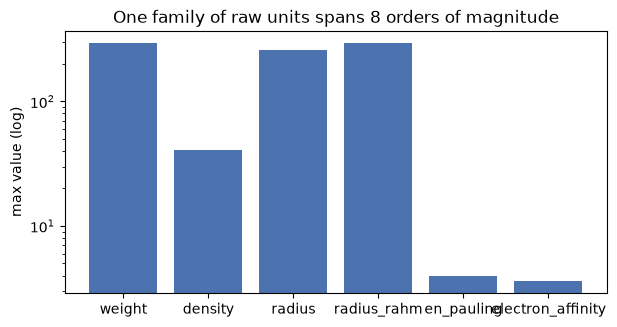

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(het.index.str.replace("atomic_", ""), het["max"], color="#4C72B0")
ax.set_yscale("log"); ax.set_ylabel("max value (log)")
ax.set_title("One family of raw units spans 8 orders of magnitude")
plt.show()

## 3. Missingness is physics (and one beautiful exception)

Noble gases don't form bonds → no electronegativity... **except xenon (Xe = 2.6)**, because
XeF₂/XeF₄ exist. Also: He and Ar have *negative* electron affinity — capturing an electron
costs energy. Missing/odd values are chemical facts, not data dirt.

In [5]:
nob = df[df.symbol.isin(["He", "Ne", "Ar", "Kr", "Xe", "Rn", "Og"])]
print(nob[["symbol", "group_id", "en_pauling", "electron_affinity"]].to_string(index=False))
print("\n→ imputation policy: median per feature, fitted inside each pipeline fold")
print("  (never globally before CV, so no information leaks across folds)")

symbol  group_id  en_pauling  electron_affinity
    He      18.0         NaN            -19.700
    Ne      18.0         NaN                NaN
    Ar      18.0         NaN            -11.500
    Kr      18.0         NaN                NaN
    Xe      18.0         2.6             -0.056
    Rn      18.0         NaN                NaN
    Og      18.0         NaN              0.056

→ imputation policy: median per feature, fitted inside each pipeline fold
  (never globally before CV, so no information leaks across folds)


## 4. The leakage rule (the experiment's honesty guarantee)

`group_id`, `period`, `block` describe the *answer* (the families). They must never enter
features — clustering happens first; the comparison comes last. Locked with an assertion:

In [6]:
FEATURES = ["atomic_weight", "density", "atomic_radius", "atomic_radius_rahm",
            "en_pauling", "electron_affinity"]
TRUTH = {"group_id", "period", "block"}
assert not (set(FEATURES) & TRUTH), "chemistry truth leaked into features!"
print("leakage guard OK: features ∩ truth = ∅")

leakage guard OK: features ∩ truth = ∅


## Takeaway

Data verified: 118 elements, 6 physical features, structured missingness with a chemical story,
truth columns quarantined. → next: `02_kmeans_study.ipynb`